### Tests for multibeam in RIS

In [1]:
# To get the parent path for the notebook
import sys
import os

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

In [2]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi

import plotly.io as pio
pio.renderers.default = 'notebook_connected' # 'browser' for avoid error but shown in the browser
import plotly.graph_objects as go

from utils.utils import *
from components.ris import RIS
from components.antenna import Antenna
from channels.tx_ris_rx_channel import tx_ris_rx_channel

In [3]:
# Create RIS
f = 28e9
lam = c/f

ris = RIS(center=[0,0,0],boresight='z',Ncol=32,Nrow=32,delta_h=lam/2,delta_v=lam/2,dx=0.47*lam,dy=0.47*lam,fc=f,radiation_factor=1,phase_shifts_dict={"0": 0,"1": pi},att_dict={"0": 1,"1": 1})

In [4]:
# Create antennas and channel
tx_pos = sph2cart([10,0,0])
tx_antenna = Antenna(tx_pos,0)

rx_pos_to30 = sph2cart([10,180,30])
rx_antenna_to30 = Antenna(rx_pos_to30,0)

rx_pos_to45 = sph2cart([10,180,45])
rx_antenna_to45 = Antenna(rx_pos_to45,0)

channel_to30 = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna_to30,ris=ris,model='Tang_general')
channel_to45 = tx_ris_rx_channel(tx_antenna=tx_antenna,rx_antenna=rx_antenna_to45,ris=ris,model='Tang_general')


Optimized state of perfect RIS:
Beamforming normalized at RX location with continuous shifts: 1.000


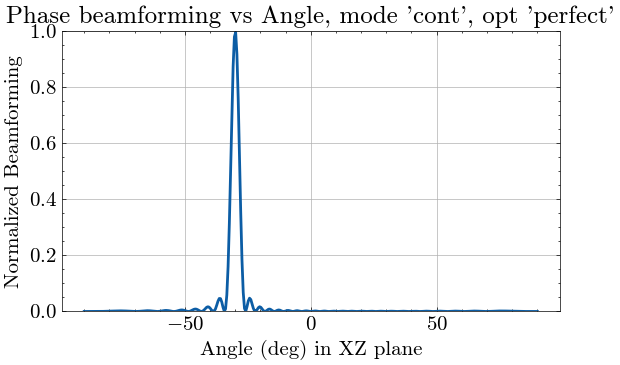

Optimized state of perfect RIS:
Beamforming normalized at RX location with continuous shifts: 1.000


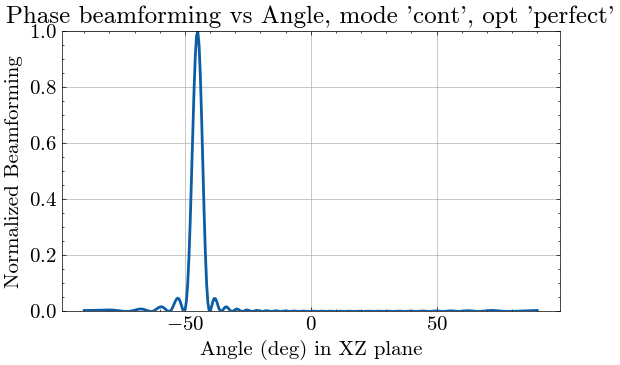

In [15]:
# Generate rx locations as a 2D map
maximum_bf = (ris.Nrow * ris.Ncol)**2

ris.reset_ris()

print("Optimized state of perfect RIS:")
channel_to30.optimize(mode='cont')
print(f"Beamforming normalized at RX location with continuous shifts: {channel_to30.phase_bf_multrx(rx_pos_to30)[0] / maximum_bf:.3f}")
channel_to30.plot_phase_bf_angle(r=10,Nr=360,axis='x')

ps_to30 = ris.get_all_phase_shifts()

ris.reset_ris()

print("Optimized state of perfect RIS:")
channel_to45.optimize(mode='cont')
print(f"Beamforming normalized at RX location with continuous shifts: {channel_to45.phase_bf_multrx(rx_pos_to45[0])[0] / maximum_bf:.3f}")
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')

ps_to45 = ris.get_all_phase_shifts()

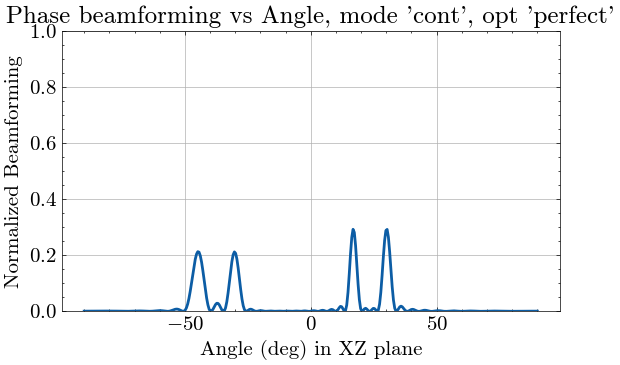

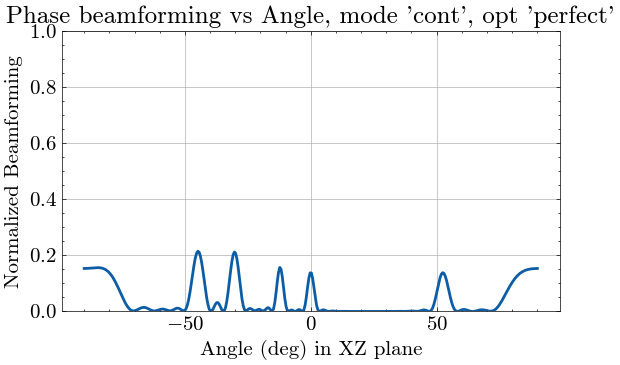

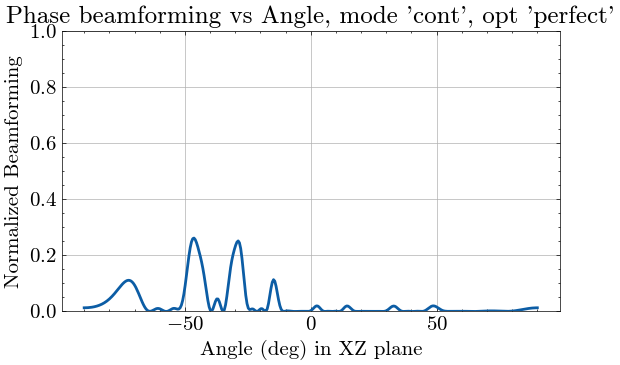

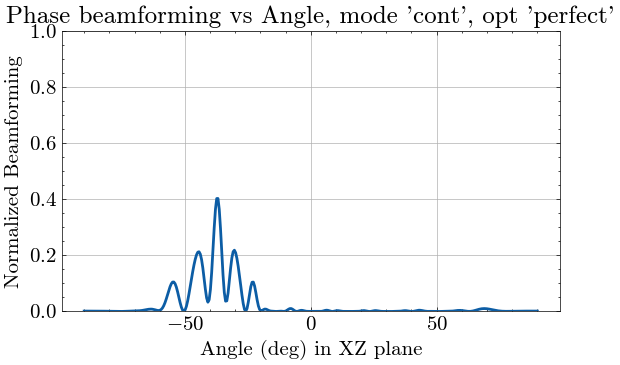

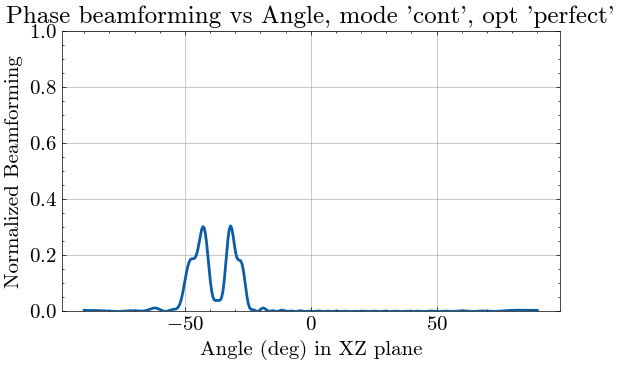

In [31]:
# Unify ps_to30 y ps_to45 alternando cada N columnas
N = 1  # Cambia este valor según lo que necesites

# Asumiendo que ps_to30 y ps_to45 son arrays 2D de tamaño (Nrow, Ncol)
ps_combined = np.zeros_like(ps_to30)
for col in range(ps_combined.shape[1]):
    if (col // N) % 2 == 0:
        ps_combined[:, col] = ps_to30[:, col]
    else:
        ps_combined[:, col] = ps_to45[:, col]

ris.reset_ris()
ris.set_all_shift(ps_combined, mode='cont')
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')

# Unify ps_to30 y ps_to45 alternando cada N columnas
N = 2  # Cambia este valor según lo que necesites

# Asumiendo que ps_to30 y ps_to45 son arrays 2D de tamaño (Nrow, Ncol)
ps_combined = np.zeros_like(ps_to30)
for col in range(ps_combined.shape[1]):
    if (col // N) % 2 == 0:
        ps_combined[:, col] = ps_to30[:, col]
    else:
        ps_combined[:, col] = ps_to45[:, col]

ris.reset_ris()
ris.set_all_shift(ps_combined, mode='cont')
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')

# Unify ps_to30 y ps_to45 alternando cada N columnas
N = 4  # Cambia este valor según lo que necesites

# Asumiendo que ps_to30 y ps_to45 son arrays 2D de tamaño (Nrow, Ncol)
ps_combined = np.zeros_like(ps_to30)
for col in range(ps_combined.shape[1]):
    if (col // N) % 2 == 0:
        ps_combined[:, col] = ps_to30[:, col]
    else:
        ps_combined[:, col] = ps_to45[:, col]

ris.reset_ris()
ris.set_all_shift(ps_combined, mode='cont')
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')

# Unify ps_to30 y ps_to45 alternando cada N columnas
N = 8  # Cambia este valor según lo que necesites

# Asumiendo que ps_to30 y ps_to45 son arrays 2D de tamaño (Nrow, Ncol)
ps_combined = np.zeros_like(ps_to30)
for col in range(ps_combined.shape[1]):
    if (col // N) % 2 == 0:
        ps_combined[:, col] = ps_to30[:, col]
    else:
        ps_combined[:, col] = ps_to45[:, col]

ris.reset_ris()
ris.set_all_shift(ps_combined, mode='cont')
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')

# Unify ps_to30 y ps_to45 alternando cada N columnas
N = 16  # Cambia este valor según lo que necesites

# Asumiendo que ps_to30 y ps_to45 son arrays 2D de tamaño (Nrow, Ncol)
ps_combined = np.zeros_like(ps_to30)
for col in range(ps_combined.shape[1]):
    if (col // N) % 2 == 0:
        ps_combined[:, col] = ps_to30[:, col]
    else:
        ps_combined[:, col] = ps_to45[:, col]

ris.reset_ris()
ris.set_all_shift(ps_combined, mode='cont')
channel_to45.plot_phase_bf_angle(r=10,Nr=360,axis='x')
